# Alquiler — 05 Segmentación por región geográfica (`okrug`)

Extensión del modelo de alquiler: en lugar de un único OLS para toda Moscú, se
**segmenta la base por región geográfica y se ajusta un OLS independiente en
cada `okrug`** (11 modelos). Cada región obtiene su propio intercepto y sus
propias pendientes, así que el efecto de la superficie, la distancia al centro,
la distancia al metro y el resto de las características puede diferir por
región — que es justo lo que un modelo global con dummies de ubicación no
permite, porque allí la región solo desplaza el intercepto. Dentro de cada
segmento se corre además **Best Subset Selection** sobre los bloques de
predictores, para comparar el modelo regional completo contra su campeón por
BIC y contra el modelo global (que es el campeón Best Subset sin segmentar).

**Reglas de trabajo:**

- Entrada: `rentals_train_fe.csv` / `rentals_test_fe.csv` (16.000 / 4.000), sin
  modificarlos. La segmentación usa el `okrug` de cada fila; el split ya
  estratificado por `okrug` garantiza que toda región esté en train y en test.
- Cada modelo regional usa los **24 predictores no locativos del modelo final
  vigente** (el bloque `okrug` es constante dentro de un segmento y sale). El
  modelo global de referencia es ese modelo final (34 columnas).
- La región de segmentación es `okrug` y no `district`: un modelo por distrito
  serían 129 modelos con ~124 filas de train cada uno para 24 predictores,
  inestables por construcción; el `okrug` deja entre 110 y 2.070 filas por
  segmento (ZelAO, el menor, se interpreta con cautela).
- Test se usa una sola vez, al final, para reportar el error por región y el
  agregado; la comparación de CV que ordena las conclusiones sale de train.
- **Fuera de alcance:** tocar los notebooks 01 a 04, reabrir la selección de
  variables, modelos que no sean OLS y cambiar la marca de modelo final
  vigente en MLflow.

## 0. Entorno y datos de entrada

Correr con el kernel **`.venv`** del proyecto. Se cargan las matrices de la
etapa de feature engineering y se definen la referencia global y el conjunto
de predictores que comparte cada segmento.

In [1]:
from pathlib import Path
import sys

RAIZ = next((b for b in [Path.cwd(), *Path.cwd().parents]
             if (b / ".env").is_file() and (b / "data").is_dir()), None)
assert RAIZ is not None, "No se encontró la raíz del proyecto (.env + data/)."
assert Path(sys.prefix).resolve() == (RAIZ / ".venv").resolve(), (
    "Seleccionar el kernel .venv del proyecto antes de continuar.")
print(f"raíz: {RAIZ} | intérprete: {sys.executable}")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from statsmodels.stats.stattools import durbin_watson

DATA_DIR = RAIZ / "data"
OUT_DIR = DATA_DIR / "processed"
Y = "log_rent"
TARGET = "monthly_rent_rub"
SEED = 42

FEATURES_BASE = [
    "log_area_z", "log_center_z", "log_metro_z", "deposit_months",
    "furnished", "pets_allowed", "rooms_2", "rooms_3", "rooms_4",
    "building_type_brick", "building_type_khrushchev",
    "building_type_modern_panel", "building_type_monolith",
    "building_type_stalin", "renovation_designer", "renovation_euro",
    "renovation_no_renovation", "okrug_CAO", "okrug_NAO", "okrug_SAO",
    "okrug_SZAO", "okrug_TAO", "okrug_VAO", "okrug_YuAO", "okrug_YuZAO",
    "okrug_ZAO", "okrug_ZelAO", "metro_line_Arbatsko-Pokrovskaya",
    "metro_line_Bolshaya Koltsevaya", "metro_line_Filyovskaya",
    "metro_line_Kalininskaya", "metro_line_Koltsevaya",
    "metro_line_Lyublinsko-Dmitrovskaya", "metro_line_MCC",
    "metro_line_Serpukhovsko-Timiryazevskaya", "metro_line_Sokolnicheskaya",
    "metro_line_Tagansko-Krasnopresnenskaya", "metro_line_Zamoskvoretskaya",
]
assert len(FEATURES_BASE) == 38 and "id" not in FEATURES_BASE
FINAL_COLS = [c for c in FEATURES_BASE
              if c != "deposit_months" and not c.startswith("rooms_")]
assert len(FINAL_COLS) == 34
NON_LOC_COLS = [c for c in FINAL_COLS if not c.startswith("okrug_")]
assert len(NON_LOC_COLS) == 24

train = pd.read_csv(OUT_DIR / "rentals_train_fe.csv")
test = pd.read_csv(OUT_DIR / "rentals_test_fe.csv")
assert train.shape[0] == 16000 and test.shape[0] == 4000
assert all(c in train.columns for c in FEATURES_BASE + [Y, TARGET, "okrug"])
SEGMENTOS = sorted(train["okrug"].unique())
assert len(SEGMENTOS) == 11 and set(test["okrug"]) == set(SEGMENTOS)
assert train[NON_LOC_COLS].isna().sum().sum() == 0
print(f"train {len(train):,} | test {len(test):,} (reservado) | target {Y}")
print(f"segmentos (okrug): {SEGMENTOS}")
print(f"predictores por segmento: {len(NON_LOC_COLS)} (sin bloque okrug)")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
FOLDS_GLOBAL = list(KFold(5, shuffle=True, random_state=SEED).split(train))


def fit_ols(cols, datos):
    X = sm.add_constant(datos[list(cols)].astype(float), has_constant="add")
    return sm.OLS(datos[Y].astype(float), X).fit()


def predecir(modelo, cols, datos):
    X = sm.add_constant(datos[list(cols)].astype(float), has_constant="add")
    return modelo.predict(X)


def cv_rmse(datos, cols):
    folds = list(KFold(5, shuffle=True, random_state=SEED).split(datos))
    Xa = datos[list(cols)].astype(float).to_numpy()
    yv = datos[Y].astype(float).to_numpy()
    rms = []
    for tri, vai in folds:
        m = LinearRegression().fit(Xa[tri], yv[tri])
        rms.append(np.sqrt(mean_squared_error(yv[vai], m.predict(Xa[vai]))))
    return float(np.mean(rms)), float(np.std(rms, ddof=1) / np.sqrt(len(rms)))

raíz: /Users/tomasmontilla/workspace/facultad/Moscow-real-estate-market--Sales-and-rentals | intérprete: /Users/tomasmontilla/workspace/facultad/Moscow-real-estate-market--Sales-and-rentals/.venv/bin/python3.14


train 16,000 | test 4,000 (reservado) | target log_rent
segmentos (okrug): ['CAO', 'NAO', 'SAO', 'SVAO', 'SZAO', 'TAO', 'VAO', 'YuAO', 'YuZAO', 'ZAO', 'ZelAO']
predictores por segmento: 24 (sin bloque okrug)


## 1. Definición de los segmentos

Un segmento por `okrug`. La tabla muestra el tamaño de cada uno en train y en
test, cuántos distritos contiene y su nivel de alquiler, porque un modelo por
región solo es defendible si cada región sostiene sus parámetros: el menor
(ZelAO, 110 filas para 24 predictores) queda señalado desde el inicio.

,n_train,n_distritos,mediana_rent,media_rent,n_test
okrug,,,,,
CAO,1194,10,102900.0,110421.0,299
ZAO,1479,12,60100.0,64869.0,370
YuZAO,1510,12,59800.0,64686.0,377
SZAO,1165,9,56300.0,61364.0,291
SAO,1894,15,47000.0,51068.0,473
VAO,1945,16,44000.0,47455.0,486
SVAO,2070,17,42600.0,45235.0,518
YuAO,2016,16,42300.0,45473.0,504
NAO,1345,11,29600.0,31037.0,337


Filas de train por segmento: mínimo 110 (ZelAO), máximo 2070; total 16,000
Un modelo por district tendría ~124 filas de train por modelo: se descarta por inestable para 24 predictores.


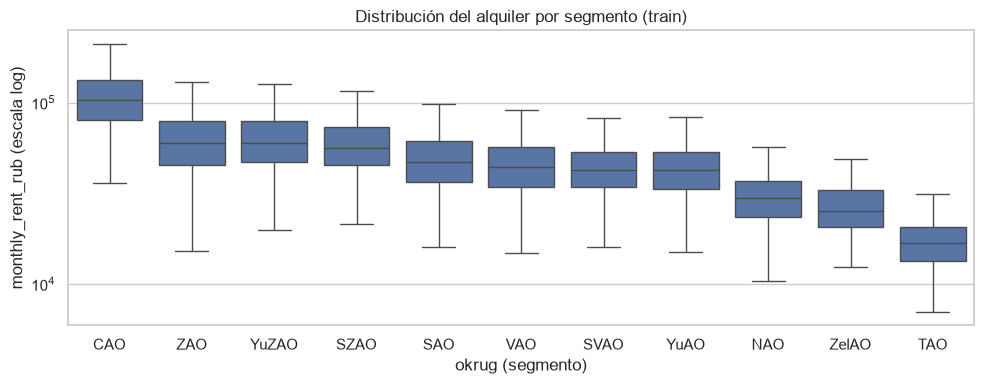

In [2]:
seg = (train.groupby("okrug")
       .agg(n_train=(TARGET, "size"), n_distritos=("district", "nunique"),
            mediana_rent=(TARGET, "median"), media_rent=(TARGET, "mean"))
       .join(test.groupby("okrug").size().rename("n_test"))
       .sort_values("mediana_rent", ascending=False))
display(seg.round(0))
print(f"Filas de train por segmento: mínimo {seg['n_train'].min()} (ZelAO), "
      f"máximo {seg['n_train'].max()}; total {seg['n_train'].sum():,}")
print(f"Un modelo por district tendría ~{16000 // train['district'].nunique()} "
      f"filas de train por modelo: se descarta por inestable para 24 predictores.")

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=train, x="okrug", y=TARGET,
            order=seg.index, ax=ax, showfliers=False)
ax.set_yscale("log")
ax.set_xlabel("okrug (segmento)"); ax.set_ylabel("monthly_rent_rub (escala log)")
ax.set_title("Distribución del alquiler por segmento (train)")
plt.tight_layout(); plt.show()

## 2. Modelo global de referencia

El punto de comparación es el modelo final vigente: un solo OLS con dummies de
`okrug`. En ese modelo la región ordena el nivel (interceptos relativos) pero
todas las pendientes son comunes; la segmentación de la sección siguiente
relaja exactamente eso.

In [3]:
modelo_global = fit_ols(FINAL_COLS, train)
cv_g, se_g = cv_rmse(train, FINAL_COLS)
# cv_rmse sobre train con FOLDS propios equivale a los folds globales (misma semilla)
print(pd.Series({
    "n_columnas": len(FINAL_COLS), "R2": modelo_global.rsquared,
    "Adj_R2": modelo_global.rsquared_adj, "AIC": modelo_global.aic,
    "BIC": modelo_global.bic, "CV_RMSE_log": cv_g, "CV_SE": se_g,
    "MAE_log_train": mean_absolute_error(train[Y], modelo_global.fittedvalues),
}).round(5).to_string())
print("\nPendientes comunes del global (predictores no locativos):")
display(modelo_global.params[NON_LOC_COLS].round(4).rename("coef_global").to_frame())

n_columnas          34.00000
R2                   0.92567
Adj_R2               0.92552
AIC             -15642.48200
BIC             -15373.66996
CV_RMSE_log          0.14846
CV_SE                0.00057
MAE_log_train        0.11874

Pendientes comunes del global (predictores no locativos):


,coef_global
log_area_z,0.2274
log_center_z,-0.1480
log_metro_z,-0.1555
furnished,0.0790
pets_allowed,-0.0266
building_type_brick,0.1282
building_type_khrushchev,-0.0772
building_type_modern_panel,0.0821
building_type_monolith,0.1794
building_type_stalin,0.2642


## 3. Ajuste segmentado: un OLS por `okrug`

En cada segmento se ajusta el mismo diseño (los 24 predictores no locativos)
solo con las filas de esa región. Si un predictor no varía dentro del segmento
(varianza cero), se descarta solo para ese segmento y queda registrado. El
diagnóstico es resumido por segmento (VIF máximo vía la inversa de la matriz
de correlaciones, skew de residuos, Durbin-Watson y Cook máximo), suficiente
para comparar 11 ajustes sin repetir la batería completa once veces.

In [4]:
def vif_maximo(datos, cols):
    v = pd.Series(np.diag(np.linalg.inv(datos[cols].astype(float).corr().to_numpy())),
                  index=cols)
    return float(v.max()), str(v.idxmax())


modelos_seg = {}
filas_seg = []
coef_seg = {}
for ok in SEGMENTOS:
    tr = train[train["okrug"] == ok]
    cols = [c for c in NON_LOC_COLS if tr[c].astype(float).std() > 0]
    descartadas = [c for c in NON_LOC_COLS if c not in cols]
    m = fit_ols(cols, tr)
    modelos_seg[ok] = {"modelo": m, "cols": cols, "descartadas": descartadas}
    coef_seg[ok] = m.params
    cv_s, se_s = cv_rmse(tr, cols)
    vmax, vcol = vif_maximo(tr, cols)
    filas_seg.append({
        "okrug": ok, "n_train": len(tr), "p": len(cols),
        "descartadas": ", ".join(descartadas) if descartadas else "—",
        "R2": float(m.rsquared), "Adj_R2": float(m.rsquared_adj),
        "AIC": float(m.aic), "BIC": float(m.bic),
        "MAE_log": float(mean_absolute_error(tr[Y], m.fittedvalues)),
        "CV_RMSE_log": cv_s, "CV_SE": se_s, "VIF_max": vmax, "VIF_col": vcol,
        "skew_resid": float(pd.Series(m.resid).skew()),
        "DW": float(durbin_watson(m.resid)),
        "Cook_max": float(m.get_influence().cooks_distance[0].max()),
    })
tabla_seg = pd.DataFrame(filas_seg).set_index("okrug")
display(tabla_seg.round(4))
cv_seg_pond = float(np.average(tabla_seg["CV_RMSE_log"], weights=tabla_seg["n_train"]))
print(f"\nCV-RMSE segmentado ponderado por n (train): {cv_seg_pond:.5f} "
      f"vs. global {cv_g:.5f} (SE {se_g:.5f})")

,n_train,p,descartadas,R2,Adj_R2,AIC,BIC,MAE_log,CV_RMSE_log,CV_SE,VIF_max,VIF_col,skew_resid,DW,Cook_max
okrug,,,,,,,,,,,,,,,
CAO,1194,24,—,0.7755,0.7709,-769.1905,-642.0639,0.1399,0.1743,0.0031,3.2165,metro_line_Koltsevaya,0.0913,2.0577,0.0238
NAO,1345,24,—,0.8295,0.8264,-1462.5027,-1332.3990,0.1117,0.1407,0.0020,2.6511,log_metro_z,-0.1450,1.9639,0.0134
SAO,1894,24,—,0.8475,0.8455,-1864.2588,-1725.5976,0.1174,0.1478,0.0027,4.6291,metro_line_Zamoskvoretskaya,-0.0724,2.0665,0.0090
SVAO,2070,24,—,0.8388,0.8369,-2498.6329,-2357.7503,0.1040,0.1325,0.0029,2.2167,log_metro_z,-0.0453,2.0505,0.0122
SZAO,1165,24,—,0.7992,0.7950,-935.3795,-808.8676,0.1282,0.1620,0.0034,6.4809,metro_line_Arbatsko-Pokrovskaya,0.0190,1.9617,0.0203
TAO,1272,24,—,0.8294,0.8261,-1564.7891,-1436.0805,0.1031,0.1317,0.0023,4.5359,log_metro_z,-0.0547,2.0273,0.0107
VAO,1945,24,—,0.8654,0.8637,-2227.7543,-2088.4289,0.1085,0.1364,0.0018,4.5860,metro_line_Arbatsko-Pokrovskaya,-0.2271,1.9498,0.0151
YuAO,2016,24,—,0.8602,0.8585,-2336.8724,-2196.6506,0.1073,0.1356,0.0003,3.2919,metro_line_Serpukhovsko-Timiryazevskaya,-0.1565,2.0004,0.0089
YuZAO,1510,24,—,0.8572,0.8549,-1584.0769,-1451.0802,0.1137,0.1431,0.0020,2.1376,log_metro_z,-0.0688,1.9504,0.0107



CV-RMSE segmentado ponderado por n (train): 0.14391 vs. global 0.14846 (SE 0.00057)


In [5]:
CLAVE = ["const", "log_area_z", "log_center_z", "log_metro_z", "furnished",
         "pets_allowed", "renovation_designer", "renovation_no_renovation",
         "building_type_stalin", "building_type_monolith"]
coef_tabla = pd.DataFrame(coef_seg).T
display(coef_tabla[CLAVE].round(4))
print("\nRango entre regiones (máx − mín) por predictor:")
rango = (coef_tabla.max() - coef_tabla.min()).sort_values(ascending=False)
display(rango.round(4).rename("rango").to_frame())
print(f"\nSignificativas al 5% por predictor clave (de {len(SEGMENTOS)} segmentos):")
sig = pd.DataFrame({ok: modelos_seg[ok]["modelo"].pvalues < 0.05 for ok in SEGMENTOS}).T
display(sig[["log_area_z", "log_center_z", "log_metro_z", "furnished",
             "renovation_designer"]].sum().rename("n_segmentos").to_frame())

,const,log_area_z,log_center_z,log_metro_z,furnished,pets_allowed,renovation_designer,renovation_no_renovation,building_type_stalin,building_type_monolith
CAO,11.0500,0.2300,-0.0483,-0.2308,0.0621,-0.0345,0.3202,-0.0976,0.2667,0.1624
NAO,10.4269,0.2348,-0.2817,-0.1025,0.0911,-0.0142,0.3091,-0.1268,0.2712,0.1829
SAO,10.5512,0.2243,-0.1498,-0.2080,0.0863,-0.0258,0.3016,-0.1156,0.2592,0.1676
SVAO,10.4658,0.2285,-0.1046,-0.1239,0.0764,-0.0256,0.3018,-0.1015,0.2651,0.1820
SZAO,10.7800,0.2201,-0.0924,-0.1463,0.0851,-0.0412,0.3327,-0.1085,0.2656,0.1803
TAO,10.0765,0.2241,-0.2252,-0.0523,0.0757,-0.0148,0.3143,-0.1058,0.2728,0.1807
VAO,10.4227,0.2304,-0.0984,-0.1786,0.0762,-0.0263,0.3189,-0.1023,0.2510,0.1878
YuAO,10.4423,0.2271,-0.1572,-0.1508,0.0765,-0.0312,0.3118,-0.1083,0.2839,0.1778
YuZAO,10.6851,0.2301,-0.1773,-0.1760,0.0846,-0.0232,0.3078,-0.1088,0.2490,0.1864
ZAO,10.8160,0.2210,-0.1901,-0.1912,0.0733,-0.0248,0.3220,-0.0995,0.2532,0.1681



Rango entre regiones (máx − mín) por predictor:


,rango
const,0.9735
log_center_z,0.2335
metro_line_Zamoskvoretskaya,0.2234
metro_line_MCC,0.2203
metro_line_Kalininskaya,0.2191
log_metro_z,0.2135
metro_line_Bolshaya Koltsevaya,0.1781
metro_line_Filyovskaya,0.1644
metro_line_Arbatsko-Pokrovskaya,0.1464
metro_line_Tagansko-Krasnopresnenskaya,0.1331



Significativas al 5% por predictor clave (de 11 segmentos):


,n_segmentos
log_area_z,11
log_center_z,10
log_metro_z,9
furnished,11
renovation_designer,11


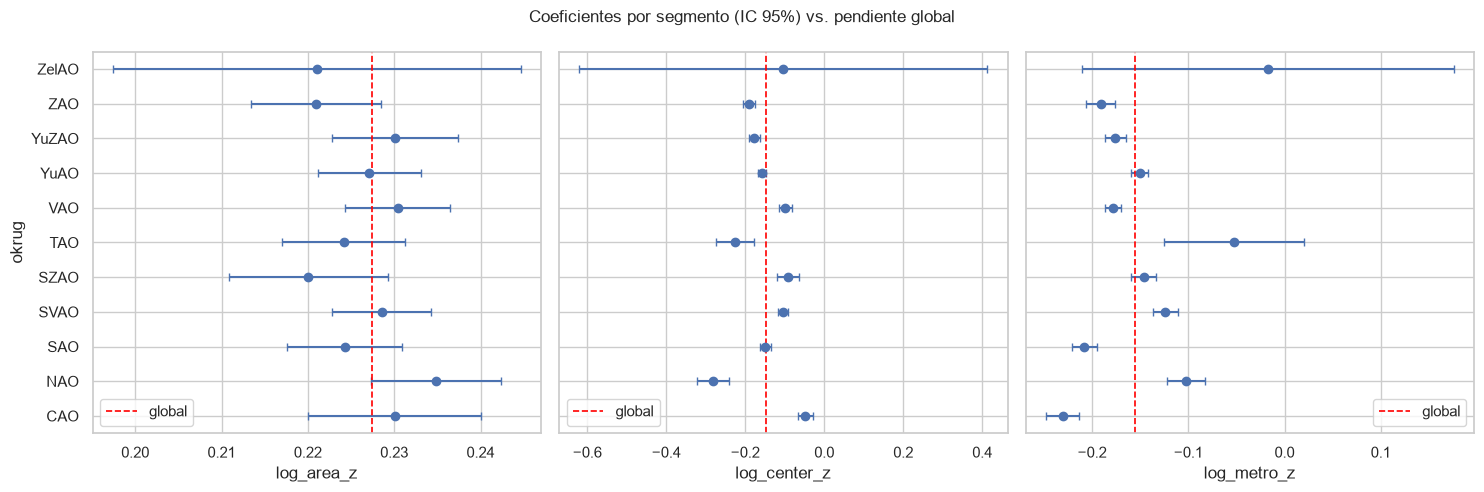

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, var in zip(axes, ["log_area_z", "log_center_z", "log_metro_z"]):
    est, err, oks = [], [], []
    for ok in SEGMENTOS:
        m = modelos_seg[ok]["modelo"]
        if var in m.params:
            oks.append(ok); est.append(m.params[var]); err.append(1.96 * m.bse[var])
    ax.errorbar(est, range(len(oks)), xerr=err, fmt="o", capsize=3)
    ax.set_yticks(range(len(oks))); ax.set_yticklabels(oks)
    ax.axvline(float(modelo_global.params[var]), color="red", ls="--", lw=1.2,
               label="global")
    ax.set_xlabel(var); ax.legend(loc="best")
axes[0].set_ylabel("okrug")
fig.suptitle("Coeficientes por segmento (IC 95%) vs. pendiente global", fontsize=12)
plt.tight_layout(); plt.show()

**Lectura del ajuste segmentado.** Los 11 modelos ajustan con tamaños muy
distintos y R² entre 0,78 (CAO) y 0,87 (ZelAO): no son comparables con el
0,9257 del global, porque el R² global también captura las diferencias de
nivel *entre* regiones, que dentro de un segmento ya no existen para explicar.
Lo comparable es el CV: el promedio ponderado por tamaño es 0,14391 contra
0,14846 del global, una mejora que ya aparece en train sin tocar test.

La heterogeneidad de pendientes es real pero selectiva. El intercepto recorre
casi un punto de log (TAO 10,076 a CAO 11,050), que es el nivel de cada
mercado regional. Entre las pendientes, lo que más cambia es la geografía
interna: la distancia al centro va de −0,282 en NAO a −0,048 en CAO (dentro
del centro, alejarse del centro pesa poco porque todo el segmento ya es
central; en la periferia pesa mucho) y la distancia al metro de −0,231 en CAO
a −0,017 en ZelAO. En cambio, la superficie es prácticamente la misma
pendiente en todas partes (0,220–0,235; significativa en los 11 segmentos),
igual que `furnished` y `renovation_designer` (11 de 11): el núcleo del precio
es estable y lo regional es el peso de la ubicación fina. El diagnóstico
resumido no muestra problemas nuevos: VIF máximo ≤ 6,48, Durbin-Watson entre
1,89 y 2,07, skew de residuos entre −0,35 y 0,09; solo ZelAO combina lo
esperado de un segmento chico (Cook máximo 0,097, `log_center` y `log_metro`
no significativas con p = 0,69 y 0,86), por lo que sus coeficientes se leen
como provisorios.

## 4. Best Subset Selection dentro de cada segmento

La segmentación dejó 11 modelos completos de 24 predictores. La pregunta que
sigue es si cada región necesita todos: se corre **Best Subset exhaustivo por
segmento** sobre 8 unidades — las 5 individuales (`log_area_z`, `log_center_z`,
`log_metro_z`, `furnished`, `pets_allowed`) y los bloques `building_type` (5),
`renovation` (3) y `metro_line` (11) —, es decir 2^8 = 256 subconjuntos por
región evaluados con la matriz de Gram (RSS exactos, sin reajustar), con
campeón por **mínimo BIC**, el mismo criterio con el que el modelo global de
referencia ganó su selección. El global con el que todo se compara es ese
campeón Best Subset sin segmentar (34 columnas).

In [7]:
import itertools

UNIDADES_SEG = {
    "log_area_z": ["log_area_z"], "log_center_z": ["log_center_z"],
    "log_metro_z": ["log_metro_z"], "furnished": ["furnished"],
    "pets_allowed": ["pets_allowed"],
    "building_type": [c for c in NON_LOC_COLS if c.startswith("building_type_")],
    "renovation": [c for c in NON_LOC_COLS if c.startswith("renovation_")],
    "metro_line": [c for c in NON_LOC_COLS if c.startswith("metro_line_")],
}
assert sum(len(v) for v in UNIDADES_SEG.values()) == 24

modelos_bss = {}
filas_bss = []
for ok in SEGMENTOS:
    tr = train[train["okrug"] == ok]
    avail = modelos_seg[ok]["cols"]
    unidades = {u: [c for c in cs if c in avail]
                for u, cs in UNIDADES_SEG.items()}
    unidades = {u: cs for u, cs in unidades.items() if cs}
    Xmat = np.column_stack([np.ones(len(tr)), tr[avail].astype(float).to_numpy()])
    yv = tr[Y].astype(float).to_numpy()
    XtX, Xty, yty = Xmat.T @ Xmat, Xmat.T @ yv, float(yv @ yv)
    pos = {c: i + 1 for i, c in enumerate(avail)}
    nombres_u = list(unidades.keys())
    n_seg = len(tr)
    mejor = None
    for k in range(len(nombres_u) + 1):
        for combo in itertools.combinations(nombres_u, k):
            idx = [0] + [pos[c] for u in combo for c in unidades[u]]
            try:
                beta = np.linalg.solve(XtX[np.ix_(idx, idx)], Xty[idx])
            except np.linalg.LinAlgError:
                continue
            rss = yty - float(Xty[idx] @ beta)
            bic = n_seg * np.log(rss / n_seg) + len(idx) * np.log(n_seg)
            if mejor is None or bic < mejor[0]:
                mejor = (bic, combo)
    combo_gan = mejor[1]
    cols_bss = [c for c in NON_LOC_COLS
                if c in {x for u in combo_gan for x in unidades[u]}]
    m_bss = fit_ols(cols_bss, tr)
    modelos_bss[ok] = {"modelo": m_bss, "cols": cols_bss, "unidades": list(combo_gan)}
    cv_b, se_b = cv_rmse(tr, cols_bss)
    fila_full = tabla_seg.loc[ok]
    filas_bss.append({
        "okrug": ok, "n_train": n_seg,
        "full_p": int(fila_full["p"]), "full_BIC": float(fila_full["BIC"]),
        "full_CV": float(fila_full["CV_RMSE_log"]),
        "bss_unidades": len(combo_gan), "bss_p": len(cols_bss),
        "bss_BIC": float(m_bss.bic), "bss_CV": cv_b, "bss_CV_SE": se_b,
        "fuera": ", ".join([u for u in nombres_u if u not in combo_gan]) or "—",
        "bss_R2": float(m_bss.rsquared),
    })
tabla_bss = pd.DataFrame(filas_bss).set_index("okrug")
display(tabla_bss.round(5))
cv_bss_pond = float(np.average(tabla_bss["bss_CV"], weights=tabla_bss["n_train"]))
print(f"CV ponderado (train): segmentado completo {cv_seg_pond:.5f} | "
      f"segmentado BSS {cv_bss_pond:.5f} | global BSS {cv_g:.5f}")
print(f"Segmentos donde el campeón BSS conserva el modelo completo: "
      f"{(tabla_bss['fuera'] == '—').sum()} de {len(tabla_bss)}")

,n_train,full_p,full_BIC,full_CV,bss_unidades,bss_p,bss_BIC,bss_CV,bss_CV_SE,fuera,bss_R2
okrug,,,,,,,,,,,
CAO,1194,24,-642.06391,0.17427,7,13,-664.48247,0.17717,0.00320,metro_line,0.76479
NAO,1345,24,-1332.39896,0.14071,6,12,-1396.93558,0.14059,0.00230,"pets_allowed, metro_line",0.82670
SAO,1894,24,-1725.59764,0.14784,7,13,-1744.95431,0.14954,0.00281,metro_line,0.84225
SVAO,2070,24,-2357.75027,0.13252,7,13,-2427.19447,0.13203,0.00295,metro_line,0.83767
SZAO,1165,24,-808.86759,0.16199,8,24,-808.86759,0.16199,0.00343,—,0.79922
TAO,1272,24,-1436.08049,0.13169,5,11,-1510.72421,0.13085,0.00231,"log_metro_z, pets_allowed, metro_line",0.82688
VAO,1945,24,-2088.42886,0.13635,8,24,-2088.42886,0.13635,0.00182,—,0.86537
YuAO,2016,24,-2196.65063,0.13555,8,24,-2196.65063,0.13555,0.00026,—,0.86020
YuZAO,1510,24,-1451.08024,0.14310,8,24,-1451.08024,0.14310,0.00204,—,0.85721


CV ponderado (train): segmentado completo 0.14391 | segmentado BSS 0.14428 | global BSS 0.14846
Segmentos donde el campeón BSS conserva el modelo completo: 4 de 11


**Lectura de Best Subset por segmento.** El campeón BIC poda en 7 de las 11
regiones y conserva el modelo completo en 4 (SZAO, VAO, YuAO, YuZAO). Lo que
más sale es el bloque `metro_line` (fuera en 6 regiones: con la región ya
fijada por la segmentación, la línea aporta menos que sus 11 parámetros);
`pets_allowed` sale en 3 y las distancias solo se caen donde no eran
significativas (ZelAO pierde `log_center_z` y `log_metro_z`; TAO,
`log_metro_z`). El núcleo — superficie, tipo de edificio y renovación — no
sale en ninguna región.

Como en la selección del modelo global, BIC y predicción no cuentan lo mismo:
el BIC mejora donde poda (ZelAO −64,7 → −112,0; TAO −1.436 → −1.511), pero el
CV ponderado del conjunto BSS (0,14428) queda levemente por encima del
segmentado completo (0,14391), ambos por debajo del global (0,14846). La
poda es defendible por parsimonia región por región, no por error: la
confirmación en test de las tres variantes va en la sección siguiente.

## 5. Evaluación en test (única): global BSS vs. segmentado vs. segmentado BSS

Se abre test una sola vez para reportar el MAE en RUB por región y el
agregado de las tres variantes: el modelo global (campeón Best Subset sin
segmentar), el segmentado completo y el segmentado con su campeón Best Subset
por región. La lectura ya fue ordenada por el CV de train; estos números
confirman o matizan, no reordenan.

In [8]:
filas_test = []
for ok in SEGMENTOS:
    te = test[test["okrug"] == ok]
    pl_g = predecir(modelo_global, FINAL_COLS, te)
    pl_s = predecir(modelos_seg[ok]["modelo"], modelos_seg[ok]["cols"], te)
    pl_b = predecir(modelos_bss[ok]["modelo"], modelos_bss[ok]["cols"], te)
    filas_test.append({
        "okrug": ok, "n_test": len(te),
        "MAE_RUB_global": mean_absolute_error(te[TARGET], np.expm1(pl_g)),
        "MAE_RUB_segmentado": mean_absolute_error(te[TARGET], np.expm1(pl_s)),
        "MAE_RUB_bss": mean_absolute_error(te[TARGET], np.expm1(pl_b)),
        "R2_RUB_global": r2_score(te[TARGET], np.expm1(pl_g)),
        "R2_RUB_segmentado": r2_score(te[TARGET], np.expm1(pl_s)),
        "R2_RUB_bss": r2_score(te[TARGET], np.expm1(pl_b)),
    })
tabla_test_seg = pd.DataFrame(filas_test).set_index("okrug")
tabla_test_seg["delta_seg"] = (tabla_test_seg["MAE_RUB_segmentado"]
                               - tabla_test_seg["MAE_RUB_global"])
tabla_test_seg["delta_bss"] = (tabla_test_seg["MAE_RUB_bss"]
                               - tabla_test_seg["MAE_RUB_global"])
display(tabla_test_seg.round(2))

pred_g_test = predecir(modelo_global, FINAL_COLS, test)
pred_s_test = pd.concat([predecir(modelos_seg[ok]["modelo"], modelos_seg[ok]["cols"], g)
                         for ok, g in test.groupby("okrug", sort=True)]).reindex(test.index)
pred_b_test = pd.concat([predecir(modelos_bss[ok]["modelo"], modelos_bss[ok]["cols"], g)
                         for ok, g in test.groupby("okrug", sort=True)]).reindex(test.index)
mae_g_test = mean_absolute_error(test[TARGET], np.expm1(pred_g_test))
mae_s_test = mean_absolute_error(test[TARGET], np.expm1(pred_s_test))
mae_b_test = mean_absolute_error(test[TARGET], np.expm1(pred_b_test))
print(f"MAE test agregado  global BSS: {mae_g_test:,.0f} | segmentado: {mae_s_test:,.0f} | "
      f"segmentado BSS: {mae_b_test:,.0f} RUB/mes")
print(f"Segmentado vs. global: {mae_s_test - mae_g_test:+,.0f} "
      f"({(mae_s_test / mae_g_test - 1) * 100:+.1f}%) | "
      f"BSS vs. global: {mae_b_test - mae_g_test:+,.0f} "
      f"({(mae_b_test / mae_g_test - 1) * 100:+.1f}%) | "
      f"BSS vs. segmentado: {mae_b_test - mae_s_test:+,.0f}")
print(f"Regiones donde mejora el segmentado: {(tabla_test_seg['delta_seg'] < 0).sum()} de 11 | "
      f"donde mejora el BSS segmentado: {(tabla_test_seg['delta_bss'] < 0).sum()} de 11")

,n_test,MAE_RUB_global,MAE_RUB_segmentado,MAE_RUB_bss,R2_RUB_global,R2_RUB_segmentado,R2_RUB_bss,delta_seg,delta_bss
okrug,,,,,,,,,
CAO,299,16949.79,15842.83,16460.59,0.70,0.75,0.73,-1106.96,-489.20
NAO,337,3362.02,3380.69,3371.50,0.83,0.82,0.82,18.67,9.48
SAO,473,6071.90,5644.66,5891.92,0.83,0.85,0.85,-427.24,-179.98
SVAO,518,4613.03,4483.26,4503.34,0.86,0.86,0.86,-129.77,-109.69
SZAO,291,8882.97,8423.98,8423.98,0.78,0.79,0.79,-458.99,-458.99
TAO,318,1869.50,1854.39,1849.78,0.82,0.83,0.83,-15.10,-19.72
VAO,486,5273.99,5099.04,5099.04,0.86,0.87,0.87,-174.95,-174.95
YuAO,504,5038.38,4943.48,4943.48,0.85,0.86,0.86,-94.90,-94.90
YuZAO,377,8050.93,7650.39,7650.39,0.82,0.84,0.84,-400.54,-400.54


MAE test agregado  global BSS: 6,458 | segmentado: 6,172 | segmentado BSS: 6,267 RUB/mes
Segmentado vs. global: -286 (-4.4%) | BSS vs. global: -191 (-3.0%) | BSS vs. segmentado: +95
Regiones donde mejora el segmentado: 9 de 11 | donde mejora el BSS segmentado: 9 de 11


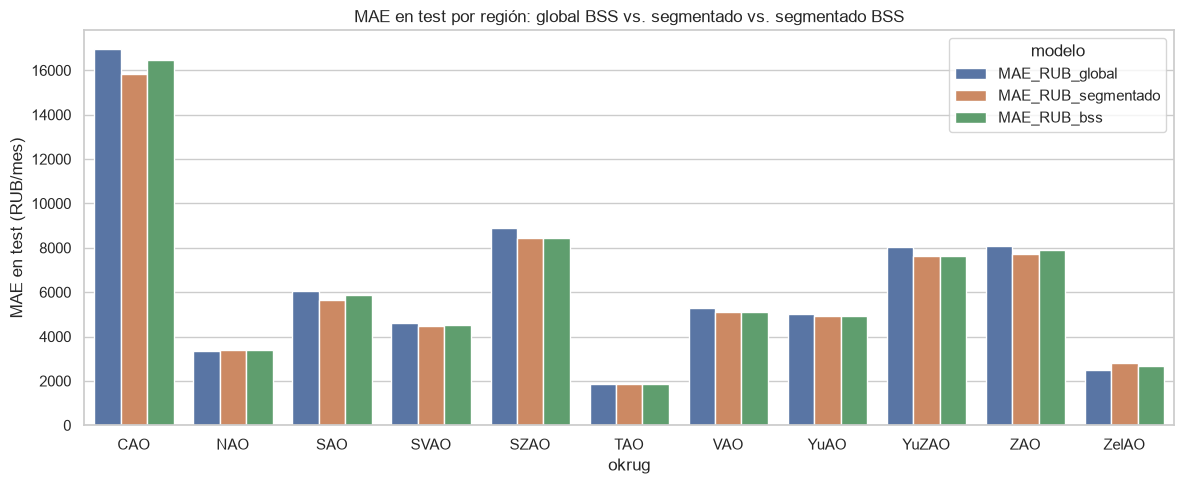

In [9]:
plot_df = tabla_test_seg.reset_index().melt(
    id_vars="okrug",
    value_vars=["MAE_RUB_global", "MAE_RUB_segmentado", "MAE_RUB_bss"],
    var_name="modelo", value_name="MAE_RUB")
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=plot_df, x="okrug", y="MAE_RUB", hue="modelo", ax=ax)
ax.set_xlabel("okrug"); ax.set_ylabel("MAE en test (RUB/mes)")
ax.set_title("MAE en test por región: global BSS vs. segmentado vs. segmentado BSS")
plt.tight_layout(); plt.show()

**Lectura de test.** El orden que anticipó el CV se confirma con tres
variantes: global BSS 6.458, segmentado BSS 6.267 y segmentado completo
6.172 RUB/mes. Segmentar le gana al mejor modelo sin segmentar incluso con la
poda por región (−191 RUB, −3,0%), y el segmentado completo le gana a su
versión podada por 95 RUB: dentro de cada región, los bloques que el BIC
descarta (sobre todo `metro_line`) sí aportaban predicción, aunque no
alcanzaran a pagar su costo en el criterio de información. Por región, el
segmentado completo mejora en 9 de 11 y el BSS segmentado también supera o
iguala al global en la mayoría, con las mismas dos excepciones de siempre en
el extremo chico (ZelAO sigue por encima del global en ambas variantes
segmentadas: 2.798 completo y 2.688 BSS contra 2.500).

## 6. Registro en MLflow (experimento `Alquiler`)

Un run por modelo regional: 11 `OLS_Segmento_<okrug>` (completos) y 11
`OLS_Segmento_BSS_<okrug>` (campeones Best Subset de cada región), con los
parámetros del segmento, sus métricas de train (incluido el CV propio), el
MAE de test por región como reporte posterior y el modelo `statsmodels` de
esa región. No se modifican los runs existentes ni la marca de modelo final
vigente.

In [10]:
# Configuración MLflow / DagsHub (mismo patrón que la etapa de modelado)
import os
from importlib.metadata import version

assert Path(sys.prefix).resolve() == (RAIZ / ".venv").resolve()
archivo_env = RAIZ / ".env"
import subprocess
assert subprocess.run(["git", "check-ignore", "-q", ".env"], cwd=RAIZ,
                      capture_output=True).returncode == 0, ".env debe estar ignorado por Git"
assert subprocess.run(["git", "ls-files", "--error-unmatch", ".env"], cwd=RAIZ,
                      capture_output=True).returncode != 0, ".env no debe estar versionado"
from dotenv import load_dotenv
load_dotenv(dotenv_path=archivo_env, override=True)
assert os.environ.get("DAGSHUB_USER_TOKEN", "").strip(), "Falta DAGSHUB_USER_TOKEN en .env"
print("Credencial cargada desde .env (ignorado y no versionado).")

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
import dagshub
import mlflow
import mlflow.statsmodels
from dagshub.common.api import RepoAPI
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient

tracking_uri_dagshub = "https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow"
assert mlflow.active_run() is None
RepoAPI("matiasgastonlonghino/MOSCOW_IDA", host="https://dagshub.com").get_repo_info()
dagshub.init(repo_owner="matiasgastonlonghino", repo_name="MOSCOW_IDA",
             mlflow=True, dvc=False, patch_mlflow=False)
mlflow.set_tracking_uri(tracking_uri_dagshub)
assert mlflow.get_tracking_uri().rstrip("/") == tracking_uri_dagshub
experimento = mlflow.set_experiment("Alquiler")
print(f"tracking: {tracking_uri_dagshub} | experimento: {experimento.name} "
      f"(id {experimento.experiment_id})")
VERSIONES = {n: version(n) for n in
             ["statsmodels", "numpy", "pandas", "scipy", "scikit-learn", "mlflow", "dagshub"]}
print("versiones:", VERSIONES)

Credencial cargada desde .env (ignorado y no versionado).


/Users/tomasmontilla/workspace/facultad/Moscow-real-estate-market--Sales-and-rentals/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Accessing as MontillaTomas

Initialized MLflow to track repo "matiasgastonlonghino/MOSCOW_IDA"

Repository matiasgastonlonghino/MOSCOW_IDA initialized!

tracking: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow | experimento: Alquiler (id 2)
versiones: {'statsmodels': '0.15.0', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'mlflow': '3.16.1', 'dagshub': '0.7.3'}


In [11]:
def registrar_segmento(ok):
    assert mlflow.active_run() is None
    info_seg = modelos_seg[ok]
    modelo, cols = info_seg["modelo"], info_seg["cols"]
    fila = tabla_seg.loc[ok]
    mae_region = float(tabla_test_seg.loc[ok, "MAE_RUB_segmentado"])
    nombre_run = f"OLS_Segmento_{ok}"
    parametros = {
        "nombre_modelo": nombre_run, "tipo_modelo": "statsmodels.OLS",
        "metodo": "segmentacion_por_okrug", "segmento_okrug": ok, "target": Y,
        "n_predictoras": len(cols), "n_train_segmento": int(fila["n_train"]),
        "n_test_segmento": int(tabla_test_seg.loc[ok, "n_test"]),
        "predictoras_descartadas": ", ".join(info_seg["descartadas"]) or "ninguna",
        "division": "80/20 de 02 (sin re-dividir)", "intercepto": True,
        "experimento": "Alquiler",
    }
    metricas = {
        "r2_log_train": float(modelo.rsquared),
        "r2_adj_log_train": float(modelo.rsquared_adj),
        "mae_log_train": float(fila["MAE_log"]),
        "cv_rmse_log_train": float(fila["CV_RMSE_log"]),
        "cv_se_log_train": float(fila["CV_SE"]),
        "aic": float(modelo.aic), "bic": float(modelo.bic),
        "vif_max_train": float(fila["VIF_max"]),
        "mae_rub_test_region": mae_region,
        "mae_rub_test_agregado_segmentado": float(mae_s_test),
        "mae_rub_test_agregado_global": float(mae_g_test),
    }
    tr = train[train["okrug"] == ok]
    diseno = sm.add_constant(tr[list(cols)].astype(float), has_constant="add")
    with mlflow.start_run(experiment_id=experimento.experiment_id,
                          run_name=nombre_run) as run:
        mlflow.log_params(parametros)
        mlflow.log_metrics({k: float(v) for k, v in metricas.items()})
        mlflow.log_text(modelo.summary().as_text(), "resumen_ols.txt")
        coef = pd.DataFrame({
            "variable": modelo.params.index, "coeficiente": modelo.params.to_numpy(),
            "std_err": modelo.bse.to_numpy(), "t_value": modelo.tvalues.to_numpy(),
            "p_value": modelo.pvalues.to_numpy(),
            "significativo_005": modelo.pvalues.to_numpy() < 0.05})
        mlflow.log_text(coef.to_csv(index=False), "coeficientes.csv")
        mlflow.log_dict({"predictoras": list(cols)}, "variables_predictoras.json")
        info = mlflow.statsmodels.log_model(
            modelo, name="modelo",
            signature=infer_signature(diseno.head(5), modelo.predict(diseno.head(5))),
            pip_requirements=[f"{p}=={VERSIONES[p]}" for p in
                              ["statsmodels", "numpy", "pandas", "scipy", "mlflow"]])
        mlflow.log_dict({"model_uri": info.model_uri}, "modelo_uri.json")
        return {"run_id": run.info.run_id, "model_uri": info.model_uri,
                "metricas": metricas, "parametros": parametros}


registros_seg = {}
for ok in SEGMENTOS:
    registros_seg[ok] = registrar_segmento(ok)
    print(f"OLS_Segmento_{ok}: FINISHED {registros_seg[ok]['run_id']}")
assert mlflow.active_run() is None

def registrar_bss(ok):
    assert mlflow.active_run() is None
    info_b = modelos_bss[ok]
    modelo, cols = info_b["modelo"], info_b["cols"]
    fila = tabla_bss.loc[ok]
    nombre_run = f"OLS_Segmento_BSS_{ok}"
    parametros = {
        "nombre_modelo": nombre_run, "tipo_modelo": "statsmodels.OLS",
        "metodo": "segmentacion_okrug_best_subset", "segmento_okrug": ok,
        "criterio_seleccion": "bic_minimo_exhaustivo_8_unidades",
        "unidades_seleccionadas": ", ".join(info_b["unidades"]), "target": Y,
        "n_predictoras": len(cols), "n_train_segmento": int(fila["n_train"]),
        "n_test_segmento": int(tabla_test_seg.loc[ok, "n_test"]),
        "division": "80/20 de 02 (sin re-dividir)", "intercepto": True,
        "experimento": "Alquiler",
    }
    metricas = {
        "r2_log_train": float(modelo.rsquared),
        "r2_adj_log_train": float(modelo.rsquared_adj),
        "cv_rmse_log_train": float(fila["bss_CV"]),
        "cv_se_log_train": float(fila["bss_CV_SE"]),
        "aic": float(modelo.aic), "bic": float(modelo.bic),
        "mae_rub_test_region": float(tabla_test_seg.loc[ok, "MAE_RUB_bss"]),
        "mae_rub_test_agregado_bss": float(mae_b_test),
        "mae_rub_test_agregado_segmentado": float(mae_s_test),
        "mae_rub_test_agregado_global": float(mae_g_test),
    }
    tr = train[train["okrug"] == ok]
    diseno = sm.add_constant(tr[list(cols)].astype(float), has_constant="add")
    with mlflow.start_run(experiment_id=experimento.experiment_id,
                          run_name=nombre_run) as run:
        mlflow.log_params(parametros)
        mlflow.log_metrics({k: float(v) for k, v in metricas.items()})
        mlflow.log_text(modelo.summary().as_text(), "resumen_ols.txt")
        coef = pd.DataFrame({
            "variable": modelo.params.index, "coeficiente": modelo.params.to_numpy(),
            "std_err": modelo.bse.to_numpy(), "t_value": modelo.tvalues.to_numpy(),
            "p_value": modelo.pvalues.to_numpy(),
            "significativo_005": modelo.pvalues.to_numpy() < 0.05})
        mlflow.log_text(coef.to_csv(index=False), "coeficientes.csv")
        mlflow.log_dict({"predictoras": list(cols),
                         "unidades": info_b["unidades"]},
                        "variables_predictoras.json")
        info = mlflow.statsmodels.log_model(
            modelo, name="modelo",
            signature=infer_signature(diseno.head(5), modelo.predict(diseno.head(5))),
            pip_requirements=[f"{p}=={VERSIONES[p]}" for p in
                              ["statsmodels", "numpy", "pandas", "scipy", "mlflow"]])
        mlflow.log_dict({"model_uri": info.model_uri}, "modelo_uri.json")
        return {"run_id": run.info.run_id, "model_uri": info.model_uri,
                "metricas": metricas, "parametros": parametros}


registros_bss = {}
for ok in SEGMENTOS:
    registros_bss[ok] = registrar_bss(ok)
    print(f"OLS_Segmento_BSS_{ok}: FINISHED {registros_bss[ok]['run_id']}")
assert mlflow.active_run() is None

🏃 View run OLS_Segmento_CAO at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2/runs/8781e204e6954b50a2b9ef8314a6b80c
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2


OLS_Segmento_CAO: FINISHED 8781e204e6954b50a2b9ef8314a6b80c


🏃 View run OLS_Segmento_NAO at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2/runs/348ea661445246ecb5352c8ba1b44647
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2


OLS_Segmento_NAO: FINISHED 348ea661445246ecb5352c8ba1b44647


🏃 View run OLS_Segmento_SAO at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2/runs/f69224ed832147b6950f48a5aab80bf1
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2


...

OLS_Segmento_BSS_YuZAO: FINISHED 7510b93c964043318ec94b9fe536fc8f


🏃 View run OLS_Segmento_BSS_ZAO at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2/runs/adde1a62585e4d0b88b671aa22a941fa
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2


OLS_Segmento_BSS_ZAO: FINISHED adde1a62585e4d0b88b671aa22a941fa


🏃 View run OLS_Segmento_BSS_ZelAO at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2/runs/5c13803bf14a4408974e0558a0065f40
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2


OLS_Segmento_BSS_ZelAO: FINISHED 5c13803bf14a4408974e0558a0065f40


In [12]:
# Verificación remota de los 22 runs (modelos recuperados: un completo y un BSS)
import math
cliente = MlflowClient(tracking_uri=tracking_uri_dagshub)
todos_runs = {f"OLS_Segmento_{ok}": reg for ok, reg in registros_seg.items()}
todos_runs.update({f"OLS_Segmento_BSS_{ok}": reg for ok, reg in registros_bss.items()})
assert len(todos_runs) == 22
verificacion = []
for nombre_run, reg in todos_runs.items():
    remoto = cliente.get_run(reg["run_id"])
    assert remoto.info.status == "FINISHED", nombre_run
    assert remoto.data.tags["mlflow.runName"] == nombre_run, nombre_run
    for k, v in reg["parametros"].items():
        assert remoto.data.params[k] == str(v), (nombre_run, k)
    for k, v in reg["metricas"].items():
        assert math.isclose(remoto.data.metrics[k], float(v),
                            rel_tol=1e-9, abs_tol=1e-12), (nombre_run, k)
    rutas = {a.path for a in cliente.list_artifacts(reg["run_id"])}
    assert {"resumen_ols.txt", "coeficientes.csv", "variables_predictoras.json",
            "modelo_uri.json"} <= rutas, nombre_run
    verificacion.append({"run": nombre_run, "run_id": reg["run_id"][:8] + "...",
                         "estado": remoto.info.status, "n_artefactos": len(rutas)})
for nombre_run, fuente, ok in [("OLS_Segmento_YuAO", modelos_seg, "YuAO"),
                               ("OLS_Segmento_BSS_ZelAO", modelos_bss, "ZelAO")]:
    reg = todos_runs[nombre_run]
    modelo_ref, cols_ref = fuente[ok]["modelo"], fuente[ok]["cols"]
    recuperado = mlflow.statsmodels.load_model(reg["model_uri"])
    tr = train[train["okrug"] == ok]
    diseno_ref = sm.add_constant(tr[cols_ref].astype(float), has_constant="add")
    np.testing.assert_allclose(recuperado.predict(diseno_ref.head(20)),
                               modelo_ref.predict(diseno_ref.head(20)),
                               rtol=1e-8, atol=1e-6)
display(pd.DataFrame(verificacion))
print(f"22 runs verificados en el experimento 'Alquiler': "
      f"{tracking_uri_dagshub}/#/experiments/{experimento.experiment_id}")
print("Modelos OLS_Segmento_YuAO y OLS_Segmento_BSS_ZelAO recuperados del "
      "servidor con predicciones idénticas (20 filas cada uno).")

,run,run_id,estado,n_artefactos
0,OLS_Segmento_CAO,8781e204...,FINISHED,4
1,OLS_Segmento_NAO,348ea661...,FINISHED,4
2,OLS_Segmento_SAO,f69224ed...,FINISHED,4
3,OLS_Segmento_SVAO,89fec94d...,FINISHED,4
4,OLS_Segmento_SZAO,b79b0494...,FINISHED,4
5,OLS_Segmento_TAO,0735f2d7...,FINISHED,4
6,OLS_Segmento_VAO,041c0eae...,FINISHED,4
7,OLS_Segmento_YuAO,97a65d91...,FINISHED,4
8,OLS_Segmento_YuZAO,efbd473b...,FINISHED,4
9,OLS_Segmento_ZAO,fe2135b1...,FINISHED,4


22 runs verificados en el experimento 'Alquiler': https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/2
Modelos OLS_Segmento_YuAO y OLS_Segmento_BSS_ZelAO recuperados del servidor con predicciones idénticas (20 filas cada uno).


## Cierre — qué deja la segmentación

- **Qué se hizo:** se partió train por `okrug` y se ajustaron 11 OLS
  independientes con los 24 predictores no locativos del modelo final. Cada
  región estima su intercepto y sus pendientes; el modelo global queda como
  referencia, no como insumo de los segmentados.
- **Dónde están las diferencias regionales:** en el nivel (interceptos de
  10,076 en TAO a 11,050 en CAO) y en el peso de la ubicación interna — la
  distancia al centro varía de −0,282 (NAO) a −0,048 (CAO) y la distancia al
  metro de −0,231 (CAO) a −0,017 (ZelAO) —, mientras el núcleo del precio es
  estable entre regiones (superficie 0,220–0,235, significativa en los 11
  segmentos; `furnished` y renovación designer también). La segmentación
  muestra que lo regional no es "todo el modelo", sino cómo cotiza moverse
  dentro de cada región.
- **Cuánto vale en error:** CV de train ponderado 0,14391 contra 0,14846 del
  global, y en test un MAE agregado de 6.172 contra 6.458 RUB/mes (−4,4%),
  con mejora en 9 de 11 regiones. El costo aparece donde el segmento es
  chico: ZelAO (110 filas de train) empeora en test (+298 RUB) y sus
  coeficientes de distancia no son significativos; es la tensión clásica de
  segmentar, menos información compartida a cambio de pendientes propias.
- **Best Subset por región:** el campeón BIC poda en 7 de 11 regiones (el
  bloque `metro_line` sale en 6) y mejora el BIC local, pero no el error: CV
  ponderado 0,14428 contra 0,14391 del segmentado completo y, en test,
  6.267 contra 6.172 RUB/mes — ambos segmentados por debajo del global BSS
  (6.458). La poda se defiende por parsimonia, no por predicción.
- **Alcance:** esta extensión convive con el modelo global vigente, no lo
  reemplaza ni cambia su marca en MLflow. Los 11 modelos regionales quedan
  registrados como runs `OLS_Segmento_<okrug>` y `OLS_Segmento_BSS_<okrug>`
  para su uso y comparación.
- **Fuera de alcance:** segmentar por `district` (129 modelos con ~124 filas
  de train cada uno, inestables para 24 predictores), interacciones como
  sustituto de la segmentación y modelos que no sean OLS.